# Rakuten Full Dataset - Exploratory Data Analysis

## 1. Setup & Configuration

In [1]:
# Standard libraries
import gzip
import json
import warnings
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from tqdm import tqdm

warnings.filterwarnings('ignore')

# Plotting configuration
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")
%matplotlib inline

# Set display options
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.max_colwidth', 100)

print("✅ Libraries imported successfully")

✅ Libraries imported successfully


In [ ]:
DATA_DIR = Path("Training-Data/")

TAXONOMY_FILE = DATA_DIR / "product_classification_taxonomy.csv"
TRAIN_FILE = DATA_DIR / "train.jsonl.gz"
PRDTYPE_COUNTS = DATA_DIR / "train_prdtypecode_value_counts.csv"
PRODUCTTYPE_COUNTS = DATA_DIR / "train_producttype_value_counts.csv"
SAMPLE_FILE = DATA_DIR / "train_sample_5.jsonl"

# Verify files exist
print("📂 Checking data files...")
for file_path in [TAXONOMY_FILE, TRAIN_FILE, PRDTYPE_COUNTS, PRODUCTTYPE_COUNTS]:
    if file_path.exists():
        size_mb = file_path.stat().st_size / (1024 * 1024)
        print(f"  ✅ {file_path.name}: {size_mb:.2f} MB")
    else:
        print(f"  ❌ {file_path.name}: NOT FOUND")

📂 Checking data files...
  ✅ product_classification_taxonomy.csv: 0.25 MB
  ✅ train.jsonl.gz: 1356.32 MB
  ✅ train_prdtypecode_value_counts.csv: 0.00 MB
  ✅ train_producttype_value_counts.csv: 0.19 MB


---
## 2. Load Metadata & Taxonomy

### 2.1 Load Taxonomy Structure

In [3]:
# Load full taxonomy
taxonomy_df = pd.read_csv(TAXONOMY_FILE)

print("="*80)
print("📊 TAXONOMY STRUCTURE")
print("="*80)
print(f"\nTotal taxonomy entries: {len(taxonomy_df):,}")
print(f"\nColumns: {list(taxonomy_df.columns)}")
print("\nFirst few entries:")
print(taxonomy_df.head(10))

# Unique values at each level
print("\n📊 Hierarchy Levels:")
print(f"  Level 1 (prdtypecode): {taxonomy_df['prdtypecode'].nunique()} unique parent categories")
print(f"  Level 1 (Typelabel): {taxonomy_df['Typelabel'].nunique()} unique parent labels")
print(f"  Level 2 (type_de_produit): {taxonomy_df['type_de_produit'].nunique()} unique product types")

# Create mappings
prdtype_to_label = taxonomy_df.groupby('prdtypecode')['Typelabel'].first().to_dict()
prdtype_to_products = taxonomy_df.groupby('prdtypecode')['type_de_produit'].apply(list).to_dict()

print("\n✅ Created taxonomy mappings")

📊 TAXONOMY STRUCTURE

Total taxonomy entries: 6,604

Columns: ['prdtypecode', 'Typelabel', 'type_de_produit']

First few entries:
   prdtypecode              Typelabel                         type_de_produit
0         2220  Accessoire animalerie                               Abreuvoir
1         2220  Accessoire animalerie                     Accessoire aquarium
2         2220  Accessoire animalerie                  Accessoire de dressage
3         2220  Accessoire animalerie  Accessoires de nettoyage pour aquarium
4         2220  Accessoire animalerie                              Anti-puces
5         2220  Accessoire animalerie                  Anti-stress pour chats
6         2220  Accessoire animalerie                                Aquarium
7         2220  Accessoire animalerie                            Arbre à chat
8         2220  Accessoire animalerie                           Bac à Litière
9         2220  Accessoire animalerie                  Baignoire pour oiseaux

📊 Hierarchy

In [4]:
# Analyze taxonomy structure
products_per_parent = taxonomy_df.groupby('prdtypecode')['type_de_produit'].nunique()

print("\n📊 TAXONOMY STATISTICS:")
print("  Products per parent category:")
print(f"    Mean: {products_per_parent.mean():.1f}")
print(f"    Median: {products_per_parent.median():.1f}")
print(f"    Min: {products_per_parent.min()}")
print(f"    Max: {products_per_parent.max()}")

# Top parent categories by number of product types
print("\n🏆 Top 10 Parent Categories (by number of product types):")
top_parents = products_per_parent.sort_values(ascending=False).head(10)
for i, (code, count) in enumerate(top_parents.items(), 1):
    label = prdtype_to_label[code]
    print(f"  {i:2}. [{code:>4}] {label:40} - {count:3} product types")


📊 TAXONOMY STATISTICS:
  Products per parent category:
    Mean: 39.9
    Median: 11.0
    Min: 0
    Max: 924

🏆 Top 10 Parent Categories (by number of product types):
   1. [1620] Bricolage                                - 924 product types
   2. [1760] Matériel de sport                        - 745 product types
   3. [1780] Accessoire auto                          - 276 product types
   4. [3065] Ustensiles de cuisine                    - 245 product types
   5. [2200] Accessoire Cycle et Cyclomoteur          - 170 product types
   6. [1540] Instrument de musique                    - 167 product types
   7. [4985] Vêtements et accessoires                 - 161 product types
   8. [2220] Accessoire animalerie                    - 146 product types
   9. [1320] Puériculture générale                    - 144 product types
  10. [1240] Accessoires Audio Vidéo                  - 132 product types


### 2.2 Load Pre-computed Value Counts

In [6]:
# Helper function for Gini coefficient
def calculate_gini(values):
    """Calculate Gini coefficient (0 = perfect equality, 1 = perfect inequality)"""
    sorted_values = np.sort(values)
    n = len(values)
    cumsum = np.cumsum(sorted_values)
    return (2 * np.sum((np.arange(1, n+1)) * sorted_values)) / (n * cumsum[-1]) - (n + 1) / n

# Load parent category value counts
prdtype_counts = pd.read_csv(PRDTYPE_COUNTS)

print("="*80)
print("📊 PARENT CATEGORY DISTRIBUTION (Level 1)")
print("="*80)
print(f"\nTotal parent categories: {len(prdtype_counts)}")
print(f"Total products: {prdtype_counts['count'].sum():,}")

# Add labels
prdtype_counts['label'] = prdtype_counts['prdtypecode'].map(prdtype_to_label)

print("\n🏆 Top 20 Parent Categories:")
print("="*80)
for i, row in prdtype_counts.head(20).iterrows():
    pct = row['count'] / prdtype_counts['count'].sum() * 100
    print(f"{i+1:3}. [{row['prdtypecode']:>4}] {row['label']:40} - {row['count']:>8,} ({pct:5.2f}%)")

# Class imbalance analysis
print("\n⚖️  CLASS IMBALANCE ANALYSIS:")
print(f"  Most frequent: {prdtype_counts.iloc[0]['count']:,} products ({prdtype_counts.iloc[0]['count']/prdtype_counts['count'].sum()*100:.2f}%)")
print(f"  Least frequent: {prdtype_counts.iloc[-1]['count']:,} products ({prdtype_counts.iloc[-1]['count']/prdtype_counts['count'].sum()*100:.2f}%)")
print(f"  Imbalance ratio: {prdtype_counts.iloc[0]['count']/prdtype_counts.iloc[-1]['count']:.1f}:1")
print(f"  Gini coefficient: {calculate_gini(prdtype_counts['count'].values):.3f}")

📊 PARENT CATEGORY DISTRIBUTION (Level 1)

Total parent categories: 165
Total products: 8,000,000

🏆 Top 20 Parent Categories:
  1. [1620] Bricolage                                -  722,639 ( 9.03%)
  2. [1760] Matériel de sport                        -  506,133 ( 6.33%)
  3. [1780] Accessoire auto                          -  497,771 ( 6.22%)
  4. [2200] Accessoire Cycle et Cyclomoteur          -  338,358 ( 4.23%)
  5. [3065] Ustensiles de cuisine                    -  313,923 ( 3.92%)
  6. [4985] Vêtements et accessoires                 -  274,236 ( 3.43%)
  7. [2220] Accessoire animalerie                    -  233,670 ( 2.92%)
  8. [1280] Jouet                                    -  227,730 ( 2.85%)
  9. [2522] Fournitures Papeterie                    -  204,412 ( 2.56%)
 10. [1320] Puériculture générale                    -  183,554 ( 2.29%)
 11. [2080] Loisirs créatifs                         -  166,877 ( 2.09%)
 12. [3229] Décoration Public                        -  151,912 ( 1.90%

In [7]:
# Helper function for Gini coefficient
def calculate_gini(values):
    """Calculate Gini coefficient (0 = perfect equality, 1 = perfect inequality)"""
    sorted_values = np.sort(values)
    n = len(values)
    cumsum = np.cumsum(sorted_values)
    return (2 * np.sum((np.arange(1, n+1)) * sorted_values)) / (n * cumsum[-1]) - (n + 1) / n

print("✅ Helper functions defined")

✅ Helper functions defined


In [8]:
# Load product type (leaf) value counts
producttype_counts = pd.read_csv(PRODUCTTYPE_COUNTS)

# Clean the producttype column (remove brackets and quotes)
producttype_counts['producttype'] = producttype_counts['producttype'].str.strip("[]'\"").str.strip()

print("="*80)
print("📊 PRODUCT TYPE DISTRIBUTION (Level 2 - Leaf Nodes)")
print("="*80)
print(f"\nTotal product types: {len(producttype_counts)}")
print(f"Total products: {producttype_counts['count'].sum():,}")

print("\n🏆 Top 20 Product Types:")
print("="*80)
for i, row in producttype_counts.head(20).iterrows():
    pct = row['count'] / producttype_counts['count'].sum() * 100
    print(f"{i+1:3}. {row['producttype']:50} - {row['count']:>8,} ({pct:5.2f}%)")

print("\n⚖️  LEAF NODE IMBALANCE:")
print(f"  Most frequent: {producttype_counts.iloc[0]['count']:,} products")
print(f"  Least frequent: {producttype_counts.iloc[-1]['count']:,} products")
print(f"  Imbalance ratio: {producttype_counts.iloc[0]['count']/producttype_counts.iloc[-1]['count']:.1f}:1")

📊 PRODUCT TYPE DISTRIBUTION (Level 2 - Leaf Nodes)

Total product types: 7317
Total products: 7,962,370

🏆 Top 20 Product Types:
  1. Batterie                                           -   24,042 ( 0.30%)
  2. Pièces détachées                                   -   17,163 ( 0.22%)
  3. Peinture                                           -   15,436 ( 0.19%)
  4. Housse                                             -   12,190 ( 0.15%)
  5. Support                                            -   12,143 ( 0.15%)
  6. Couverture                                         -   11,957 ( 0.15%)
  7. Sangle                                             -   11,789 ( 0.15%)
  8. Bougie                                             -   11,661 ( 0.15%)
  9. Masque                                             -   11,646 ( 0.15%)
 10. Protection                                         -   11,376 ( 0.14%)
 11. Papier                                             -   11,188 ( 0.14%)
 12. Figurine                      

---
## 3. Visualize Distribution

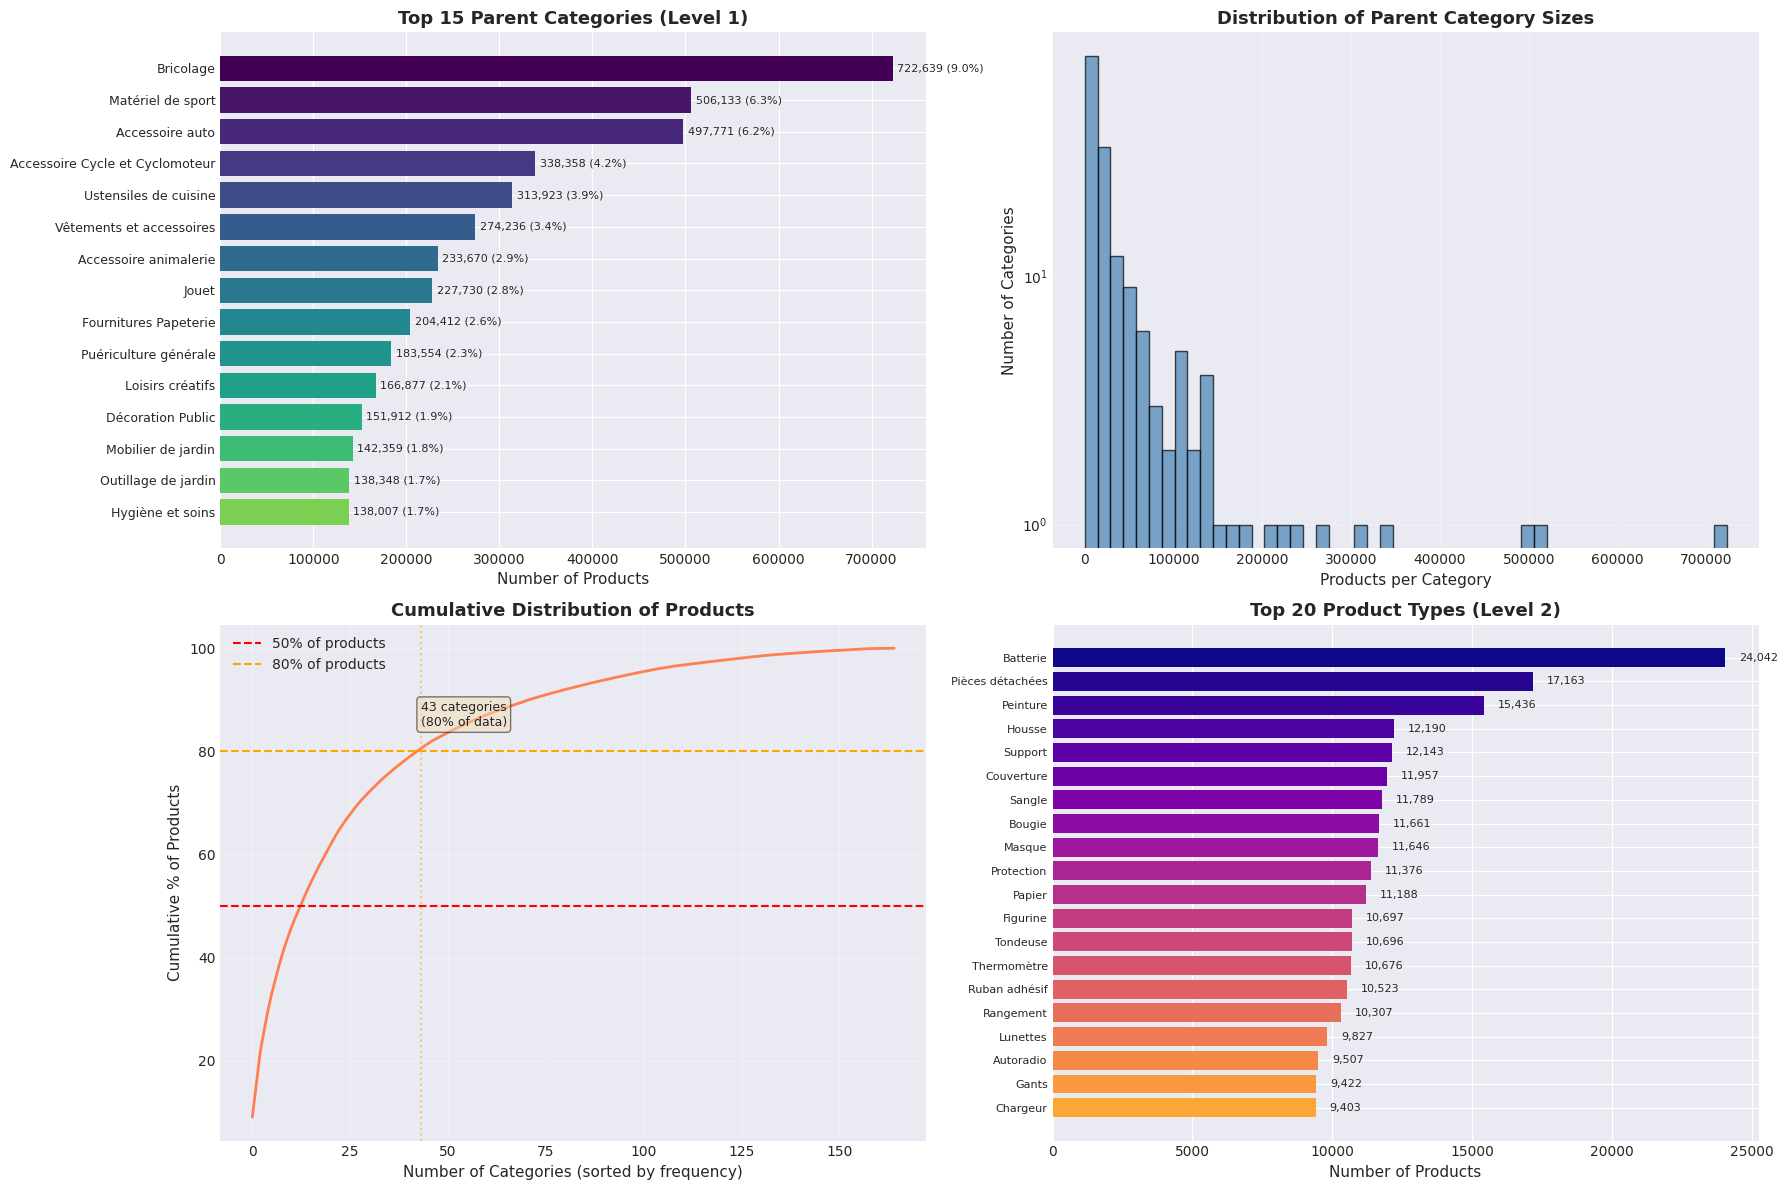


💡 Insight: 43 parent categories (out of 165) contain 80% of all products!


In [9]:
# Visualize parent category distribution
fig, axes = plt.subplots(2, 2, figsize=(18, 12))

# Top 15 parent categories
top_15 = prdtype_counts.head(15)
colors = plt.cm.viridis(np.linspace(0, 0.8, len(top_15)))

bars = axes[0, 0].barh(range(len(top_15)), top_15['count'], color=colors)
axes[0, 0].set_yticks(range(len(top_15)))
axes[0, 0].set_yticklabels(top_15['label'], fontsize=9)
axes[0, 0].set_xlabel('Number of Products', fontsize=11)
axes[0, 0].set_title('Top 15 Parent Categories (Level 1)', fontsize=13, fontweight='bold')
axes[0, 0].invert_yaxis()

# Add value labels
for i, (bar, val, pct) in enumerate(zip(bars, top_15['count'], top_15['count']/prdtype_counts['count'].sum()*100)):
    axes[0, 0].text(val + 5000, i, f"{val:,} ({pct:.1f}%)",
                    va='center', fontsize=8)

# Distribution of category sizes (log scale)
axes[0, 1].hist(prdtype_counts['count'], bins=50, color='steelblue', edgecolor='black', alpha=0.7)
axes[0, 1].set_xlabel('Products per Category', fontsize=11)
axes[0, 1].set_ylabel('Number of Categories', fontsize=11)
axes[0, 1].set_title('Distribution of Parent Category Sizes', fontsize=13, fontweight='bold')
axes[0, 1].set_yscale('log')
axes[0, 1].grid(alpha=0.3)

# Cumulative distribution
cumsum = prdtype_counts['count'].cumsum()
cumsum_pct = cumsum / cumsum.iloc[-1] * 100
axes[1, 0].plot(range(len(cumsum_pct)), cumsum_pct, linewidth=2, color='coral')
axes[1, 0].axhline(y=50, color='red', linestyle='--', label='50% of products')
axes[1, 0].axhline(y=80, color='orange', linestyle='--', label='80% of products')
axes[1, 0].set_xlabel('Number of Categories (sorted by frequency)', fontsize=11)
axes[1, 0].set_ylabel('Cumulative % of Products', fontsize=11)
axes[1, 0].set_title('Cumulative Distribution of Products', fontsize=13, fontweight='bold')
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.3)

# Find how many categories contain 80% of products
idx_80 = (cumsum_pct >= 80).idxmax()
axes[1, 0].axvline(x=idx_80, color='orange', linestyle=':', alpha=0.5)
axes[1, 0].text(idx_80, 85, f'{idx_80} categories\n(80% of data)',
                ha='left', fontsize=9, bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

# Product type distribution (top 20)
top_20_products = producttype_counts.head(20)
colors_prod = plt.cm.plasma(np.linspace(0, 0.8, len(top_20_products)))

bars_prod = axes[1, 1].barh(range(len(top_20_products)), top_20_products['count'], color=colors_prod)
axes[1, 1].set_yticks(range(len(top_20_products)))
axes[1, 1].set_yticklabels(top_20_products['producttype'], fontsize=8)
axes[1, 1].set_xlabel('Number of Products', fontsize=11)
axes[1, 1].set_title('Top 20 Product Types (Level 2)', fontsize=13, fontweight='bold')
axes[1, 1].invert_yaxis()

# Add value labels
for i, (bar, val) in enumerate(zip(bars_prod, top_20_products['count'])):
    axes[1, 1].text(val + 500, i, f"{val:,}", va='center', fontsize=8)

plt.tight_layout()
plt.savefig('rakuten_full_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"\n💡 Insight: {idx_80} parent categories (out of {len(prdtype_counts)}) contain 80% of all products!")

---
## 4. Sample Data Analysis

### 4.1 Load and Analyze Sample

In [10]:
# Load sample file to understand structure
sample_data = []
with open(SAMPLE_FILE, 'r', encoding='utf-8') as f:
    for line in f:
        sample_data.append(json.loads(line))

sample_df = pd.DataFrame(sample_data)

print("="*80)
print("📋 SAMPLE DATA STRUCTURE")
print("="*80)
print(f"\nSample size: {len(sample_df)} products")
print(f"\nColumns: {list(sample_df.columns)}")
print("\nData types:")
print(sample_df.dtypes)
print("\nFirst 3 samples:")
for i, row in sample_df.head(3).iterrows():
    print(f"\n--- Product {i+1} ---")
    print(f"ID: {row['productid']}")
    print(f"Title: {row['designation']}")
    print(f"Parent Code: {row['prdtypecode']} ({row['typelabel']})")
    print(f"Product Type: {row['producttype']}")
    print(f"Description: '{row['description'][:100]}...' (length: {len(row['description'])})" if row['description'] else "Description: (empty)")

📋 SAMPLE DATA STRUCTURE

Sample size: 5 products

Columns: ['productid', 'designation', 'prdtypecode', 'typelabel', 'producttype', 'description']

Data types:
productid      object
designation    object
prdtypecode     int64
typelabel      object
producttype    object
description    object
dtype: object

First 3 samples:

--- Product 1 ---
ID: 10701799159
Title: Baguette inox 67.60 esab
Parent Code: 1620 (Bricolage)
Product Type: ['Poste à souder']
Description: (empty)

--- Product 2 ---
ID: 12828967857
Title: Poupée Doremi (Nicole Et Emilie)
Parent Code: 2260 (Objets à collectionner)
Product Type: ['Artisanat']
Description: (empty)

--- Product 3 ---
ID: 5019852983
Title: Publicité Papier - Téléviseur Ducretet-Thomson De 1957
Parent Code: 2260 (Objets à collectionner)
Product Type: ['Dépliant']
Description: (empty)


### 4.2 Analyze Larger Sample (Streaming)

In [11]:
# Analyze first 100k products to get text statistics
print("📊 Analyzing first 100,000 products for text statistics...")
print("(This may take 1-2 minutes)\n")

SAMPLE_SIZE = 100_000
stats = {
    'title_lengths': [],
    'desc_lengths': [],
    'has_description': [],
    'producttype_list_lengths': [],
    'categories': Counter(),
    'product_types': Counter()
}

with gzip.open(TRAIN_FILE, 'rt', encoding='utf-8') as f:
    for i, line in enumerate(tqdm(f, total=SAMPLE_SIZE, desc="Processing")):
        if i >= SAMPLE_SIZE:
            break

        product = json.loads(line)

        # Title length
        stats['title_lengths'].append(len(product['designation']))

        # Description
        desc = product.get('description', '')
        stats['desc_lengths'].append(len(desc))
        stats['has_description'].append(bool(desc))

        # Product type list
        prod_types = product.get('producttype', [])
        stats['producttype_list_lengths'].append(len(prod_types))

        # Categories
        stats['categories'][product['prdtypecode']] += 1

        # Product types
        for pt in prod_types:
            stats['product_types'][pt] += 1

print("\n✅ Analysis complete!")

📊 Analyzing first 100,000 products for text statistics...
(This may take 1-2 minutes)



Processing: 100%|██████████| 100000/100000 [00:01<00:00, 52619.22it/s]


✅ Analysis complete!


In [12]:
# Display statistics
print("="*80)
print(f"📊 TEXT STATISTICS (based on {SAMPLE_SIZE:,} products)")
print("="*80)

title_lengths = np.array(stats['title_lengths'])
desc_lengths = np.array(stats['desc_lengths'])
desc_present = np.array([d for d in desc_lengths if d > 0])

print("\n📝 TITLE STATISTICS:")
print(f"  Mean length: {title_lengths.mean():.1f} characters")
print(f"  Median length: {np.median(title_lengths):.1f} characters")
print(f"  Std dev: {title_lengths.std():.1f} characters")
print(f"  Min/Max: {title_lengths.min()} / {title_lengths.max()} characters")
print("  Percentiles:")
print(f"    25th: {np.percentile(title_lengths, 25):.0f} chars")
print(f"    50th: {np.percentile(title_lengths, 50):.0f} chars")
print(f"    75th: {np.percentile(title_lengths, 75):.0f} chars")
print(f"    95th: {np.percentile(title_lengths, 95):.0f} chars")

print("\n📄 DESCRIPTION STATISTICS:")
pct_with_desc = sum(stats['has_description']) / len(stats['has_description']) * 100
print(f"  Products with description: {sum(stats['has_description']):,} ({pct_with_desc:.1f}%)")
print(f"  Products without description: {len(stats['has_description']) - sum(stats['has_description']):,} ({100-pct_with_desc:.1f}%)")

if len(desc_present) > 0:
    print("\n  When description is present:")
    print(f"    Mean length: {desc_present.mean():.1f} characters")
    print(f"    Median length: {np.median(desc_present):.1f} characters")
    print(f"    Std dev: {desc_present.std():.1f} characters")
    print(f"    Min/Max: {desc_present.min()} / {desc_present.max()} characters")
    print("    Percentiles:")
    print(f"      25th: {np.percentile(desc_present, 25):.0f} chars")
    print(f"      50th: {np.percentile(desc_present, 50):.0f} chars")
    print(f"      75th: {np.percentile(desc_present, 75):.0f} chars")
    print(f"      95th: {np.percentile(desc_present, 95):.0f} chars")

print("\n🏷️  PRODUCT TYPE LABELS:")
producttype_lengths = np.array(stats['producttype_list_lengths'])
print(f"  Products with 0 types: {sum(producttype_lengths == 0):,} ({sum(producttype_lengths == 0)/len(producttype_lengths)*100:.1f}%)")
print(f"  Products with 1 type: {sum(producttype_lengths == 1):,} ({sum(producttype_lengths == 1)/len(producttype_lengths)*100:.1f}%)")
print(f"  Products with 2+ types: {sum(producttype_lengths >= 2):,} ({sum(producttype_lengths >= 2)/len(producttype_lengths)*100:.1f}%)")
print(f"  Max types per product: {producttype_lengths.max()}")

📊 TEXT STATISTICS (based on 100,000 products)

📝 TITLE STATISTICS:
  Mean length: 120.4 characters
  Median length: 123.0 characters
  Std dev: 51.8 characters
  Min/Max: 4 / 254 characters
  Percentiles:
    25th: 78 chars
    50th: 123 chars
    75th: 163 chars
    95th: 198 chars

📄 DESCRIPTION STATISTICS:
  Products with description: 89,149 (89.1%)
  Products without description: 10,851 (10.9%)

  When description is present:
    Mean length: 834.2 characters
    Median length: 590.0 characters
    Std dev: 711.2 characters
    Min/Max: 1 / 8769 characters
    Percentiles:
      25th: 279 chars
      50th: 590 chars
      75th: 1242 chars
      95th: 2148 chars

🏷️  PRODUCT TYPE LABELS:
  Products with 0 types: 0 (0.0%)
  Products with 1 type: 99,097 (99.1%)
  Products with 2+ types: 903 (0.9%)
  Max types per product: 2


---
## 5. Text Length Visualizations

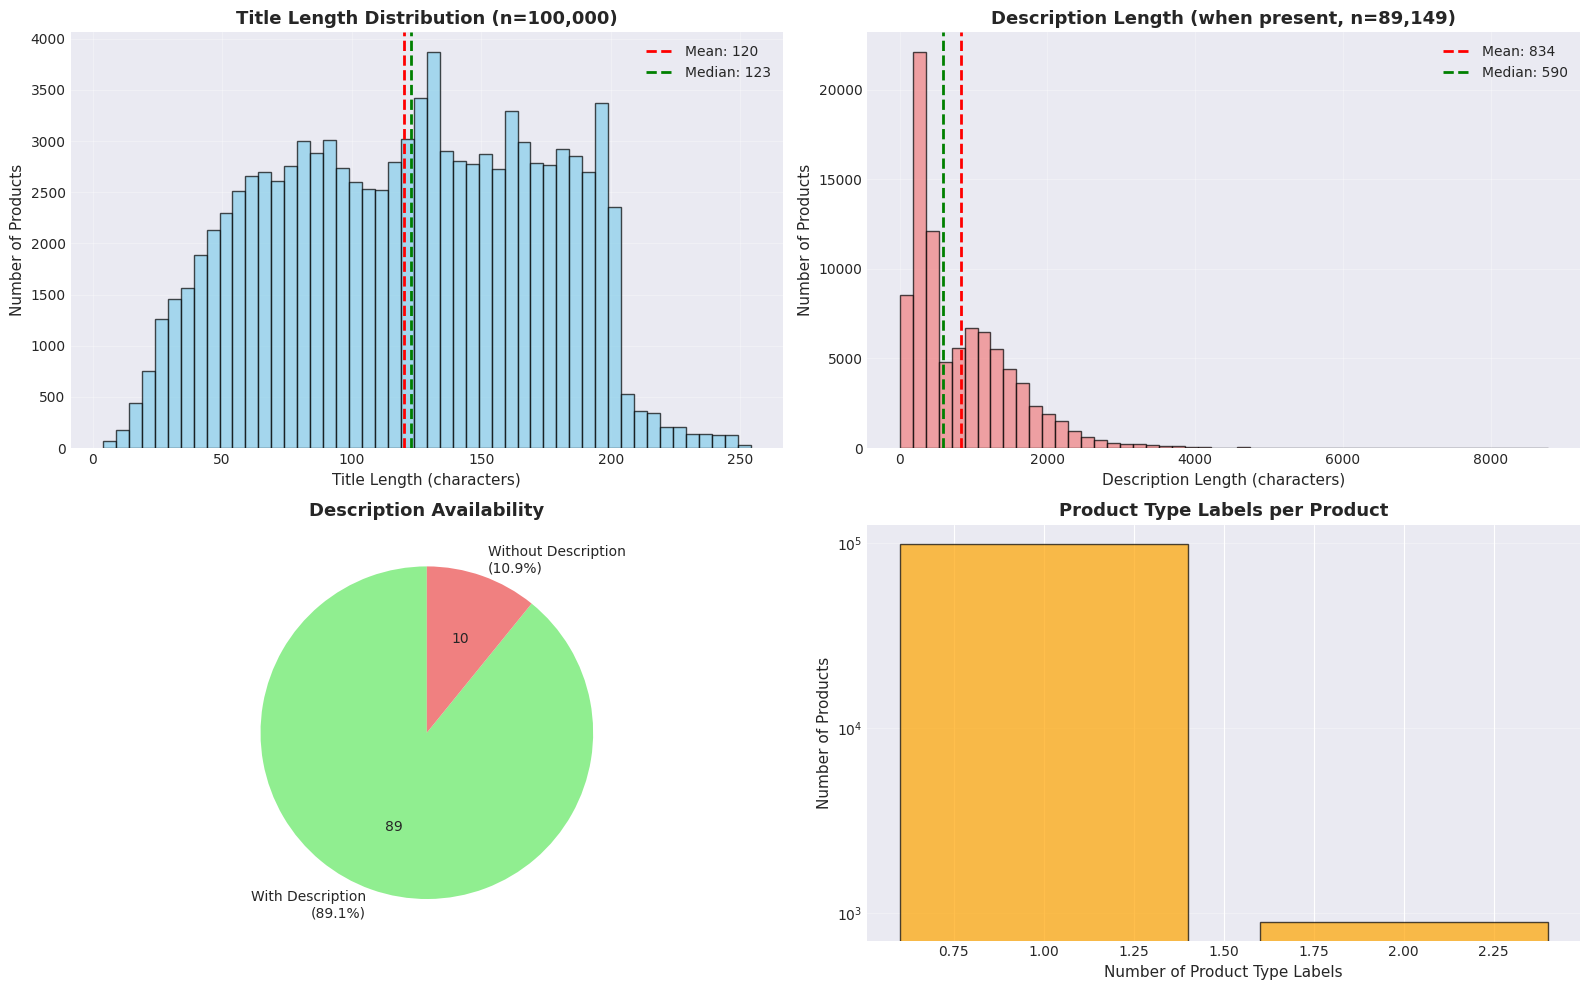

In [13]:
# Visualize text lengths
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Title length distribution
axes[0, 0].hist(title_lengths, bins=50, color='skyblue', edgecolor='black', alpha=0.7)
axes[0, 0].axvline(title_lengths.mean(), color='red', linestyle='--', linewidth=2,
                   label=f'Mean: {title_lengths.mean():.0f}')
axes[0, 0].axvline(np.median(title_lengths), color='green', linestyle='--', linewidth=2,
                   label=f'Median: {np.median(title_lengths):.0f}')
axes[0, 0].set_xlabel('Title Length (characters)', fontsize=11)
axes[0, 0].set_ylabel('Number of Products', fontsize=11)
axes[0, 0].set_title(f'Title Length Distribution (n={SAMPLE_SIZE:,})', fontsize=13, fontweight='bold')
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

# Description length distribution (when present)
if len(desc_present) > 0:
    axes[0, 1].hist(desc_present, bins=50, color='lightcoral', edgecolor='black', alpha=0.7)
    axes[0, 1].axvline(desc_present.mean(), color='red', linestyle='--', linewidth=2,
                       label=f'Mean: {desc_present.mean():.0f}')
    axes[0, 1].axvline(np.median(desc_present), color='green', linestyle='--', linewidth=2,
                       label=f'Median: {np.median(desc_present):.0f}')
axes[0, 1].set_xlabel('Description Length (characters)', fontsize=11)
axes[0, 1].set_ylabel('Number of Products', fontsize=11)
axes[0, 1].set_title(f'Description Length (when present, n={len(desc_present):,})',
                     fontsize=13, fontweight='bold')
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.3)

# Description availability pie chart
desc_avail = [sum(stats['has_description']), len(stats['has_description']) - sum(stats['has_description'])]
axes[1, 0].pie(desc_avail,
               labels=[f'With Description\n({pct_with_desc:.1f}%)',
                      f'Without Description\n({100-pct_with_desc:.1f}%)'],
               autopct='%d',
               colors=['lightgreen', 'lightcoral'],
               startangle=90)
axes[1, 0].set_title('Description Availability', fontsize=13, fontweight='bold')

# Product type labels per product
type_dist = pd.Series(producttype_lengths).value_counts().sort_index()
axes[1, 1].bar(type_dist.index, type_dist.values, color='orange', alpha=0.7, edgecolor='black')
axes[1, 1].set_xlabel('Number of Product Type Labels', fontsize=11)
axes[1, 1].set_ylabel('Number of Products', fontsize=11)
axes[1, 1].set_title('Product Type Labels per Product', fontsize=13, fontweight='bold')
axes[1, 1].set_yscale('log')
axes[1, 1].grid(alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig('rakuten_text_statistics.png', dpi=300, bbox_inches='tight')
plt.show()

---
## 6. Data Quality Analysis

In [14]:
print("="*80)
print("🔍 DATA QUALITY ASSESSMENT")
print("="*80)

# Very short titles
very_short = sum(title_lengths < 10)
print("\n📏 TITLE QUALITY:")
print(f"  Very short titles (<10 chars): {very_short:,} ({very_short/len(title_lengths)*100:.2f}%)")
short = sum((title_lengths >= 10) & (title_lengths < 20))
print(f"  Short titles (10-20 chars): {short:,} ({short/len(title_lengths)*100:.2f}%)")
normal = sum((title_lengths >= 20) & (title_lengths < 100))
print(f"  Normal titles (20-100 chars): {normal:,} ({normal/len(title_lengths)*100:.2f}%)")
long = sum(title_lengths >= 100)
print(f"  Long titles (≥100 chars): {long:,} ({long/len(title_lengths)*100:.2f}%)")

# Description quality
print("\n📄 DESCRIPTION QUALITY:")
if len(desc_present) > 0:
    very_short_desc = sum(desc_present < 20)
    print(f"  Very short descriptions (<20 chars): {very_short_desc:,} ({very_short_desc/len(desc_present)*100:.2f}% of non-empty)")
    short_desc = sum((desc_present >= 20) & (desc_present < 100))
    print(f"  Short descriptions (20-100 chars): {short_desc:,} ({short_desc/len(desc_present)*100:.2f}% of non-empty)")
    normal_desc = sum((desc_present >= 100) & (desc_present < 500))
    print(f"  Normal descriptions (100-500 chars): {normal_desc:,} ({normal_desc/len(desc_present)*100:.2f}% of non-empty)")
    long_desc = sum(desc_present >= 500)
    print(f"  Long descriptions (≥500 chars): {long_desc:,} ({long_desc/len(desc_present)*100:.2f}% of non-empty)")

# Product type labels
print("\n🏷️  LABELING QUALITY:")
no_types = sum(producttype_lengths == 0)
print(f"  Products with NO product type: {no_types:,} ({no_types/len(producttype_lengths)*100:.2f}%)")
single_type = sum(producttype_lengths == 1)
print(f"  Products with 1 product type: {single_type:,} ({single_type/len(producttype_lengths)*100:.2f}%)")
multi_type = sum(producttype_lengths > 1)
print(f"  Products with multiple types: {multi_type:,} ({multi_type/len(producttype_lengths)*100:.2f}%)")

print("\n⚠️  POTENTIAL ISSUES:")
print(f"  - {100-pct_with_desc:.1f}% of products have no description")
print(f"  - {very_short/len(title_lengths)*100:.2f}% of titles are very short (<10 chars)")
print(f"  - {no_types/len(producttype_lengths)*100:.2f}% of products have no product type label")
print(f"  - High class imbalance (Gini: {calculate_gini(prdtype_counts['count'].values):.3f})")

🔍 DATA QUALITY ASSESSMENT

📏 TITLE QUALITY:
  Very short titles (<10 chars): 99 (0.10%)
  Short titles (10-20 chars): 716 (0.72%)
  Normal titles (20-100 chars): 36,700 (36.70%)
  Long titles (≥100 chars): 62,485 (62.48%)

📄 DESCRIPTION QUALITY:
  Very short descriptions (<20 chars): 270 (0.30% of non-empty)
  Short descriptions (20-100 chars): 3,000 (3.37% of non-empty)
  Normal descriptions (100-500 chars): 38,594 (43.29% of non-empty)
  Long descriptions (≥500 chars): 47,285 (53.04% of non-empty)

🏷️  LABELING QUALITY:
  Products with NO product type: 0 (0.00%)
  Products with 1 product type: 99,097 (99.10%)
  Products with multiple types: 903 (0.90%)

⚠️  POTENTIAL ISSUES:
  - 10.9% of products have no description
  - 0.10% of titles are very short (<10 chars)
  - 0.00% of products have no product type label
  - High class imbalance (Gini: 0.689)


---
## 7. Hierarchical Structure Analysis

In [15]:
# Analyze hierarchical relationships from sample
print("="*80)
print("🌳 HIERARCHICAL STRUCTURE ANALYSIS")
print("="*80)

# Group by parent category
parent_to_children = defaultdict(set)
for _, row in taxonomy_df.iterrows():
    parent_to_children[row['prdtypecode']].add(row['type_de_produit'])

children_counts = {k: len(v) for k, v in parent_to_children.items()}
children_counts_series = pd.Series(children_counts)

print("\n📊 PARENT-CHILD RELATIONSHIPS:")
print(f"  Total parent categories: {len(parent_to_children)}")
print(f"  Total unique product types (children): {len(taxonomy_df['type_de_produit'].unique())}")
print(f"  Average children per parent: {children_counts_series.mean():.1f}")
print(f"  Median children per parent: {children_counts_series.median():.1f}")
print(f"  Max children for one parent: {children_counts_series.max()}")

# Find parents with most children
print("\n🏆 Parents with Most Product Types:")
top_parents_by_children = children_counts_series.sort_values(ascending=False).head(10)
for i, (code, count) in enumerate(top_parents_by_children.items(), 1):
    label = prdtype_to_label[code]
    print(f"  {i:2}. [{code:>4}] {label:40} - {count:3} types")

# Find parents with few children
print("\n📉 Parents with Fewest Product Types:")
bottom_parents = children_counts_series.sort_values().head(10)
for i, (code, count) in enumerate(bottom_parents.items(), 1):
    label = prdtype_to_label[code]
    print(f"  {i:2}. [{code:>4}] {label:40} - {count:3} types")

🌳 HIERARCHICAL STRUCTURE ANALYSIS

📊 PARENT-CHILD RELATIONSHIPS:
  Total parent categories: 165
  Total unique product types (children): 5857
  Average children per parent: 40.0
  Median children per parent: 11.0
  Max children for one parent: 924

🏆 Parents with Most Product Types:
   1. [1620] Bricolage                                - 924 types
   2. [1760] Matériel de sport                        - 745 types
   3. [1780] Accessoire auto                          - 276 types
   4. [3065] Ustensiles de cuisine                    - 245 types
   5. [2200] Accessoire Cycle et Cyclomoteur          - 170 types
   6. [1540] Instrument de musique                    - 167 types
   7. [4985] Vêtements et accessoires                 - 161 types
   8. [2220] Accessoire animalerie                    - 146 types
   9. [1320] Puériculture générale                    - 144 types
  10. [2585] Outillage de jardin                      - 132 types

📉 Parents with Fewest Product Types:
   1. [2402] Lot d

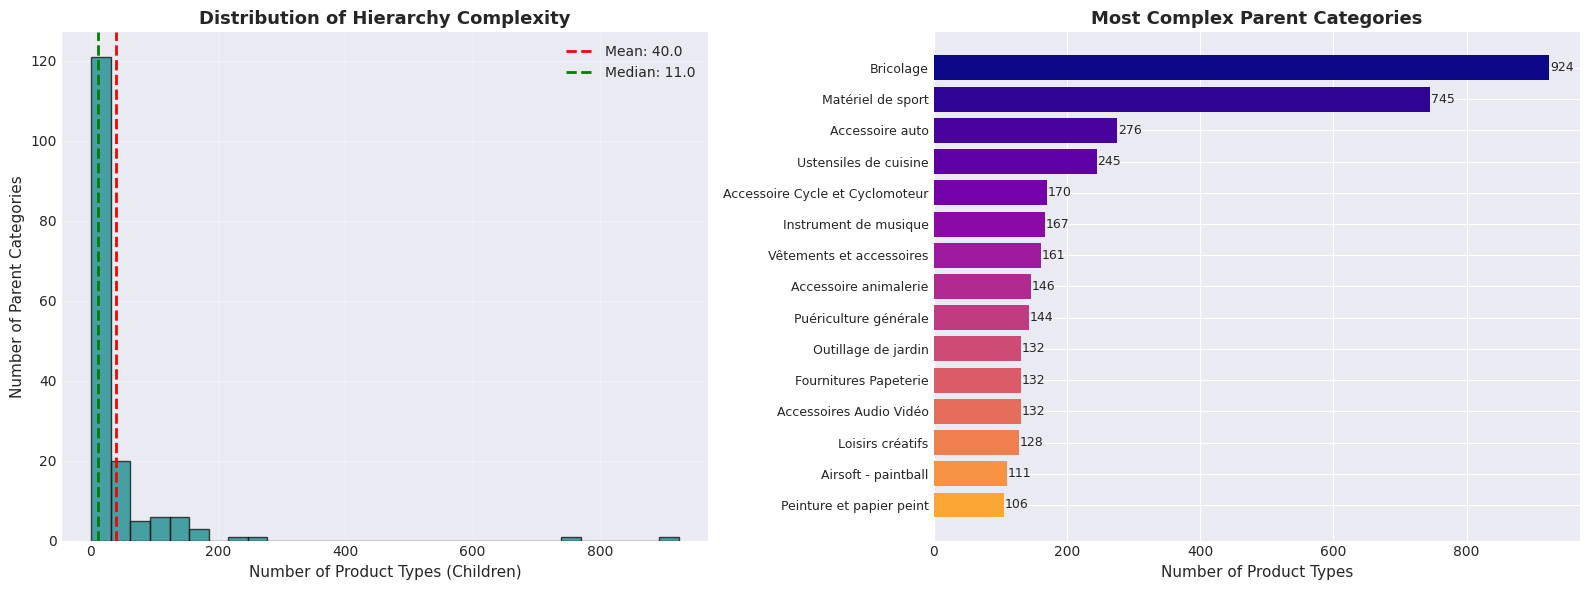

In [16]:
# Visualize hierarchy complexity
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Distribution of children per parent
axes[0].hist(children_counts_series.values, bins=30, color='teal', edgecolor='black', alpha=0.7)
axes[0].axvline(children_counts_series.mean(), color='red', linestyle='--', linewidth=2,
                label=f'Mean: {children_counts_series.mean():.1f}')
axes[0].axvline(children_counts_series.median(), color='green', linestyle='--', linewidth=2,
                label=f'Median: {children_counts_series.median():.1f}')
axes[0].set_xlabel('Number of Product Types (Children)', fontsize=11)
axes[0].set_ylabel('Number of Parent Categories', fontsize=11)
axes[0].set_title('Distribution of Hierarchy Complexity', fontsize=13, fontweight='bold')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Top 15 parents by complexity
top_complex = children_counts_series.sort_values(ascending=False).head(15)
labels_complex = [prdtype_to_label[code] for code in top_complex.index]
colors_complex = plt.cm.plasma(np.linspace(0, 0.8, len(top_complex)))

bars = axes[1].barh(range(len(top_complex)), top_complex.values, color=colors_complex)
axes[1].set_yticks(range(len(top_complex)))
axes[1].set_yticklabels(labels_complex, fontsize=9)
axes[1].set_xlabel('Number of Product Types', fontsize=11)
axes[1].set_title('Most Complex Parent Categories', fontsize=13, fontweight='bold')
axes[1].invert_yaxis()

# Add value labels
for i, (bar, val) in enumerate(zip(bars, top_complex.values)):
    axes[1].text(val + 1, i, str(val), va='center', fontsize=9)

plt.tight_layout()
plt.savefig('rakuten_hierarchy_complexity.png', dpi=300, bbox_inches='tight')
plt.show()

---
## 9. Summary Statistics for Report

In [18]:
# Create summary dictionary for easy reference
summary_stats = {
    'dataset': {
        'total_products': int(total_products),
        'parent_categories': len(prdtype_counts),
        'product_types': len(producttype_counts),
        'avg_products_per_parent': int(total_products / len(prdtype_counts)),
    },
    'text': {
        'title_mean_length': float(title_lengths.mean()),
        'title_median_length': float(np.median(title_lengths)),
        'desc_present_pct': float(pct_with_desc),
        'desc_mean_length': float(desc_present.mean()) if len(desc_present) > 0 else 0,
    },
    'imbalance': {
        'gini_coefficient': float(calculate_gini(prdtype_counts['count'].values)),
        'imbalance_ratio': float(prdtype_counts.iloc[0]['count']/prdtype_counts.iloc[-1]['count']),
        'top_category': prdtype_counts.iloc[0]['label'],
        'top_category_count': int(prdtype_counts.iloc[0]['count']),
        'top_category_pct': float(prdtype_counts.iloc[0]['count']/total_products*100),
        'categories_for_80pct': int(idx_80) + 1,
    },
    'hierarchy': {
        'avg_children_per_parent': float(children_counts_series.mean()),
        'max_children': int(children_counts_series.max()),
        'min_children': int(children_counts_series.min()),
    }
}

# Save to JSON
import json

with open('rakuten_eda_summary.json', 'w') as f:
    json.dump(summary_stats, f, indent=2)

print("="*80)
print("📊 SUMMARY STATISTICS (saved to rakuten_eda_summary.json)")
print("="*80)
print(json.dumps(summary_stats, indent=2))
print("\n✅ Summary saved!")

📊 SUMMARY STATISTICS (saved to rakuten_eda_summary.json)
{
  "dataset": {
    "total_products": 8000000,
    "parent_categories": 165,
    "product_types": 7317,
    "avg_products_per_parent": 48484
  },
  "text": {
    "title_mean_length": 120.35133,
    "title_median_length": 123.0,
    "desc_present_pct": 89.149,
    "desc_mean_length": 834.1523180293666
  },
  "imbalance": {
    "gini_coefficient": 0.6885796666666666,
    "imbalance_ratio": 14169.392156862745,
    "top_category": "Bricolage",
    "top_category_count": 722639,
    "top_category_pct": 9.0329875,
    "categories_for_80pct": 44
  },
  "hierarchy": {
    "avg_children_per_parent": 40.012121212121215,
    "max_children": 924,
    "min_children": 1
  }
}

✅ Summary saved!


In [19]:
# Install langdetect if needed
# !pip install langdetect

import warnings
from collections import Counter

from langdetect import DetectorFactory, detect

warnings.filterwarnings('ignore')

# Set seed for reproducible language detection
DetectorFactory.seed = 0

print("🌍 Analyzing language distribution...")
print("(Analyzing first 100,000 products)\n")

# Detect languages
language_stats = {
    'title_languages': [],
    'desc_languages': [],
    'both_languages': []
}

errors = {'title': 0, 'desc': 0}

# Function to safely detect language
def safe_detect(text):
    try:
        if text and len(str(text).strip()) > 10:  # Need at least 10 chars
            return detect(str(text))
        return 'unknown'
    except:
        return 'error'

# Analyze the sample we already loaded (100K products)
print("Detecting languages in titles and descriptions...")
with gzip.open(TRAIN_FILE, 'rt', encoding='utf-8') as f:
    for i, line in enumerate(tqdm(f, total=SAMPLE_SIZE, desc="Language Detection")):
        if i >= SAMPLE_SIZE:
            break

        product = json.loads(line)

        # Detect title language
        title_lang = safe_detect(product['designation'])
        language_stats['title_languages'].append(title_lang)
        if title_lang == 'error':
            errors['title'] += 1

        # Detect description language (if present)
        desc = product.get('description', '')
        if desc:
            desc_lang = safe_detect(desc)
            language_stats['desc_languages'].append(desc_lang)
            if desc_lang == 'error':
                errors['desc'] += 1

            # Track if title and desc are in different languages
            if title_lang != 'error' and desc_lang != 'error':
                language_stats['both_languages'].append((title_lang, desc_lang))

print("\n✅ Language detection complete!")

🌍 Analyzing language distribution...
(Analyzing first 100,000 products)

Detecting languages in titles and descriptions...


Language Detection: 100%|██████████| 100000/100000 [18:13<00:00, 91.47it/s]


✅ Language detection complete!


In [23]:
# Display statistics
print("="*80)
print("🌍 LANGUAGE DISTRIBUTION ANALYSIS")
print("="*80)

# Title languages
title_lang_counts = Counter(language_stats['title_languages'])
print(f"\n📝 TITLE LANGUAGES (from {len(language_stats['title_languages'])} products):")
print("="*80)
for i, (lang, count) in enumerate(title_lang_counts.most_common(15), 1):
    pct = count / len(language_stats['title_languages']) * 100
    lang_name = {
        'fr': 'French 🇫🇷',
        'en': 'English 🇬🇧',
        'de': 'German 🇩🇪',
        'es': 'Spanish 🇪🇸',
        'it': 'Italian 🇮🇹',
        'pt': 'Portuguese 🇵🇹',
        'nl': 'Dutch 🇳🇱',
        'zh-cn': 'Chinese 🇨🇳',
        'ja': 'Japanese 🇯🇵',
        'error': '❌ Detection Error',
        'unknown': '❓ Unknown'
    }.get(lang, lang.upper())

    print(f"  {i:2}. {lang_name:30} - {count:>7,} ({pct:5.2f}%)")

# Description languages
if language_stats['desc_languages']:
    desc_lang_counts = Counter(language_stats['desc_languages'])
    print(f"\n📄 DESCRIPTION LANGUAGES (from {len(language_stats['desc_languages'])} descriptions):")
    print("="*80)
    for i, (lang, count) in enumerate(desc_lang_counts.most_common(15), 1):
        pct = count / len(language_stats['desc_languages']) * 100
        lang_name = {
            'fr': 'French 🇫🇷',
            'en': 'English 🇬🇧',
            'de': 'German 🇩🇪',
            'es': 'Spanish 🇪🇸',
            'it': 'Italian 🇮🇹',
            'pt': 'Portuguese 🇵🇹',
            'nl': 'Dutch 🇳🇱',
            'zh-cn': 'Chinese 🇨🇳',
            'ja': 'Japanese 🇯🇵',
            'error': '❌ Detection Error',
            'unknown': '❓ Unknown'
        }.get(lang, lang.upper())

        print(f"  {i:2}. {lang_name:30} - {count:>7,} ({pct:5.2f}%)")

# Mixed language analysis
print("\n🔀 MIXED LANGUAGE PRODUCTS:")
print("="*80)
mixed_lang_products = [
    (t, d) for t, d in language_stats['both_languages']
    if t != d and t not in ['error', 'unknown'] and d not in ['error', 'unknown']
]
mixed_count = len(mixed_lang_products)
total_both = len(language_stats['both_languages'])
print(f"  Products with different title/description languages: {mixed_count:,} ({mixed_count/total_both*100:.2f}%)")

if mixed_count > 0:
    mixed_combos = Counter(mixed_lang_products)
    print("\n  Top 10 language combinations (Title → Description):")
    for i, ((title_lang, desc_lang), count) in enumerate(mixed_combos.most_common(10), 1):
        pct = count / mixed_count * 100
        print(f"    {i:2}. {title_lang.upper():>5} → {desc_lang.upper():<5} : {count:>5,} ({pct:4.1f}%)")

# Error rates
print("\n⚠️  DETECTION ERRORS:")
print(f"  Title detection errors: {errors['title']:,} ({errors['title']/SAMPLE_SIZE*100:.2f}%)")
print(f"  Description detection errors: {errors['desc']:,} ({errors['desc']/len(language_stats['desc_languages'])*100:.2f}%)")

🌍 LANGUAGE DISTRIBUTION ANALYSIS

📝 TITLE LANGUAGES (from 100000 products):
   1. French 🇫🇷                      -  82,359 (82.36%)
   2. English 🇬🇧                     -  11,107 (11.11%)
   3. German 🇩🇪                      -   2,552 ( 2.55%)
   4. CA                             -   1,294 ( 1.29%)
   5. Dutch 🇳🇱                       -   1,249 ( 1.25%)
   6. Spanish 🇪🇸                     -     259 ( 0.26%)
   7. Italian 🇮🇹                     -     242 ( 0.24%)
   8. RO                             -     207 ( 0.21%)
   9. Portuguese 🇵🇹                  -     151 ( 0.15%)
  10. ❓ Unknown                      -     120 ( 0.12%)
  11. NO                             -     108 ( 0.11%)
  12. ID                             -      53 ( 0.05%)
  13. TL                             -      49 ( 0.05%)
  14. AF                             -      48 ( 0.05%)
  15. ET                             -      37 ( 0.04%)

📄 DESCRIPTION LANGUAGES (from 89149 descriptions):
   1. French 🇫🇷                 

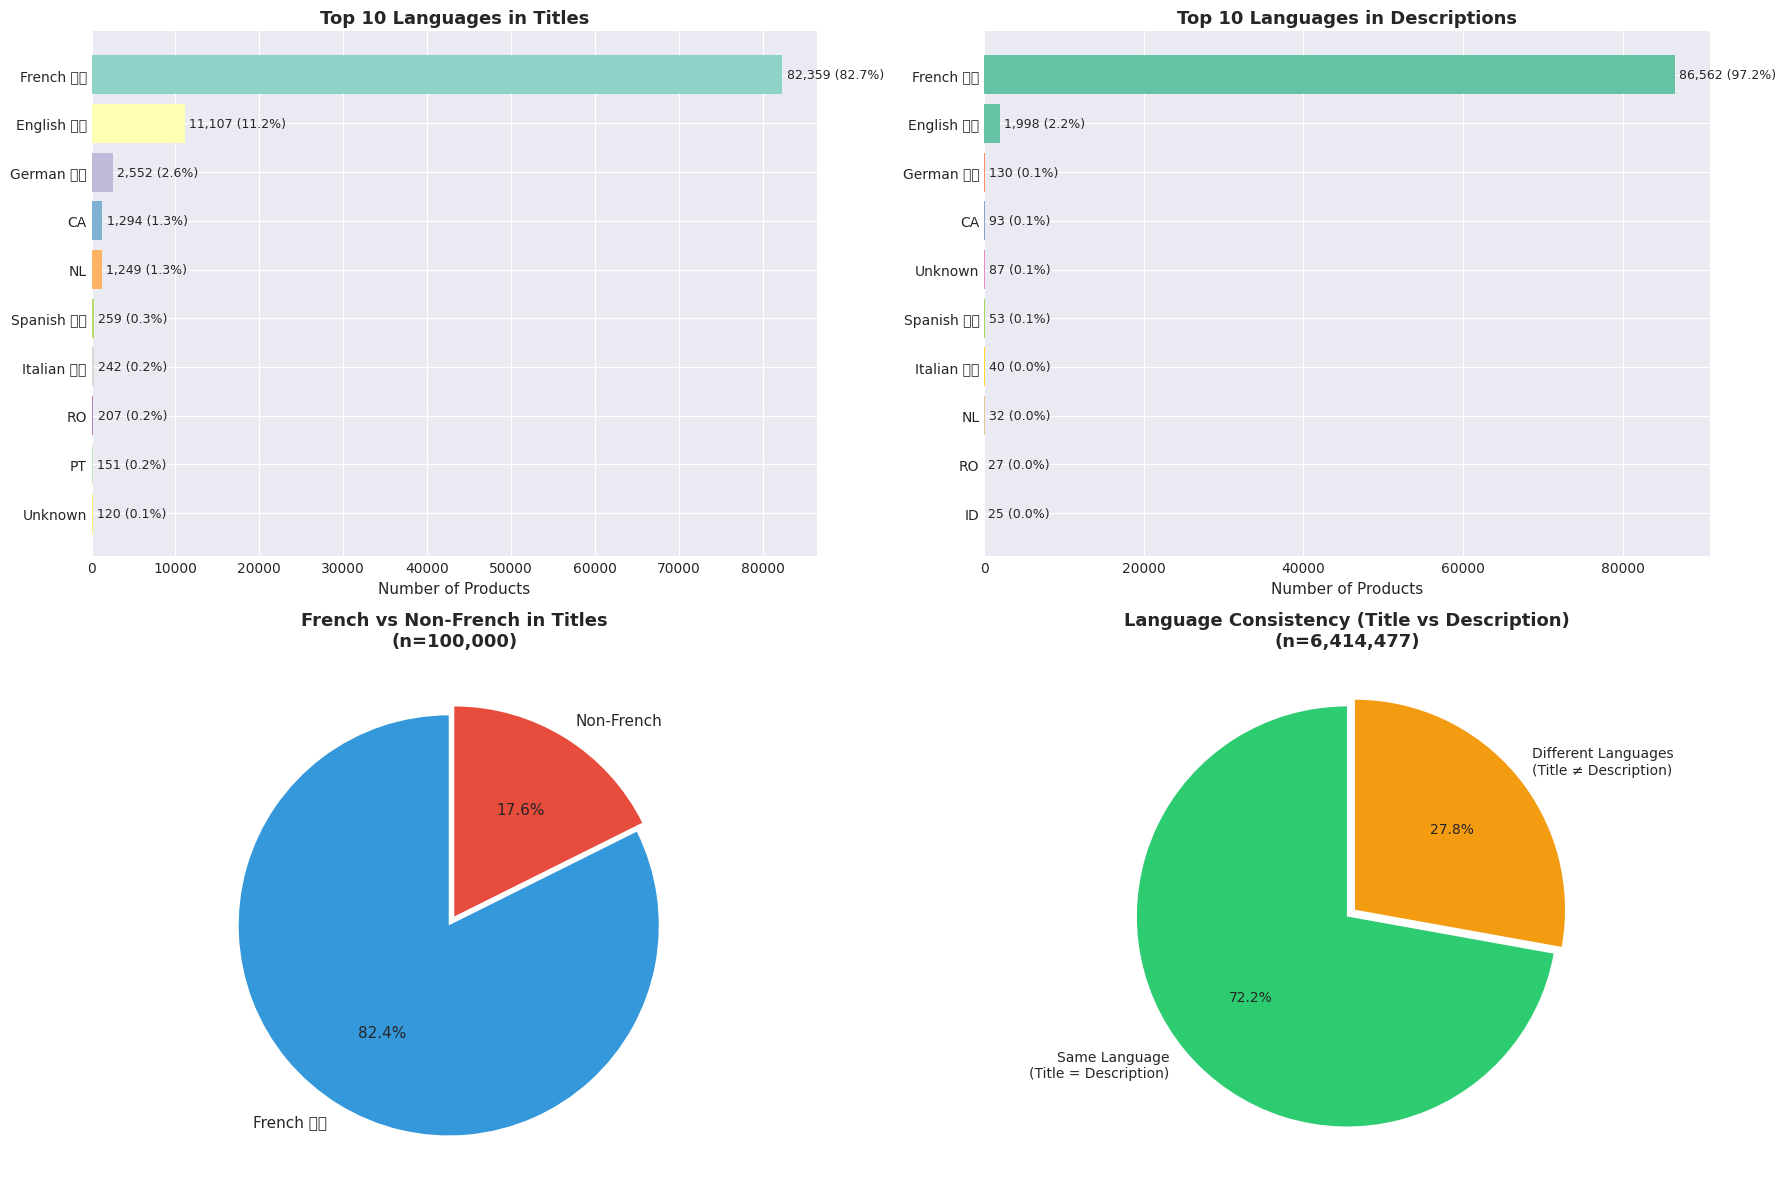


✅ Visualization saved: rakuten_language_distribution.png


In [30]:
# Visualizations
fig, axes = plt.subplots(2, 2, figsize=(18, 12))

# 1. Title language distribution (top 10)
title_top_10 = title_lang_counts.most_common(10)
langs, counts = zip(*title_top_10)
lang_labels = [
    {
        'fr': 'French 🇫🇷', 'en': 'English 🇬🇧', 'de': 'German 🇩🇪',
        'es': 'Spanish 🇪🇸', 'it': 'Italian 🇮🇹', 'zh-cn': 'Chinese 🇨🇳',
        'error': 'Error', 'unknown': 'Unknown'
    }.get(lang, lang.upper()) for lang in langs
]

colors_lang = plt.cm.Set3(np.linspace(0, 1, len(langs)))
bars1 = axes[0, 0].barh(range(len(langs)), counts, color=colors_lang)
axes[0, 0].set_yticks(range(len(langs)))
axes[0, 0].set_yticklabels(lang_labels, fontsize=10)
axes[0, 0].set_xlabel('Number of Products', fontsize=11)
axes[0, 0].set_title('Top 10 Languages in Titles', fontsize=13, fontweight='bold')
axes[0, 0].invert_yaxis()

# Add percentage labels
for i, (bar, val) in enumerate(zip(bars1, counts)):
    pct = val / sum(counts) * 100
    axes[0, 0].text(val + 500, i, f'{val:,} ({pct:.1f}%)', va='center', fontsize=9)

# 2. Description language distribution (top 10)
if language_stats['desc_languages']:
    desc_top_10 = desc_lang_counts.most_common(10)
    desc_langs, desc_counts = zip(*desc_top_10)
    desc_labels = [
        {
            'fr': 'French 🇫🇷', 'en': 'English 🇬🇧', 'de': 'German 🇩🇪',
            'es': 'Spanish 🇪🇸', 'it': 'Italian 🇮🇹', 'zh-cn': 'Chinese 🇨🇳',
            'error': 'Error', 'unknown': 'Unknown'
        }.get(lang, lang.upper()) for lang in desc_langs
    ]

    colors_desc = plt.cm.Set2(np.linspace(0, 1, len(desc_langs)))
    bars2 = axes[0, 1].barh(range(len(desc_langs)), desc_counts, color=colors_desc)
    axes[0, 1].set_yticks(range(len(desc_langs)))
    axes[0, 1].set_yticklabels(desc_labels, fontsize=10)
    axes[0, 1].set_xlabel('Number of Products', fontsize=11)
    axes[0, 1].set_title('Top 10 Languages in Descriptions', fontsize=13, fontweight='bold')
    axes[0, 1].invert_yaxis()

    # Add percentage labels
    for i, (bar, val) in enumerate(zip(bars2, desc_counts)):
        pct = val / sum(desc_counts) * 100
        axes[0, 1].text(val + 500, i, f'{val:,} ({pct:.1f}%)', va='center', fontsize=9)

# 3. Pie chart: French vs Non-French (Titles)
fr_count = title_lang_counts.get('fr', 0)
non_fr_count = sum(title_lang_counts.values()) - fr_count
labels_pie = ['French 🇫🇷', 'Non-French']
sizes_pie = [fr_count, non_fr_count]
colors_pie = ['#3498db', '#e74c3c']
explode_pie = (0.05, 0)

axes[1, 0].pie(sizes_pie, explode=explode_pie, labels=labels_pie, autopct='%1.1f%%',
               colors=colors_pie, startangle=90, textprops={'fontsize': 11})
axes[1, 0].set_title(f'French vs Non-French in Titles\n(n={sum(sizes_pie):,})',
                     fontsize=13, fontweight='bold')

# 4. Mixed language analysis
if mixed_count > 0:
    same_lang = total_both - mixed_count
    labels_mixed = ['Same Language\n(Title = Description)', 'Different Languages\n(Title ≠ Description)']
    sizes_mixed = [same_lang, mixed_count]
    colors_mixed = ['#2ecc71', '#f39c12']
    explode_mixed = (0, 0.05)

    axes[1, 1].pie(sizes_mixed, explode=explode_mixed, labels=labels_mixed, autopct='%1.1f%%',
                   colors=colors_mixed, startangle=90, textprops={'fontsize': 10})
    axes[1, 1].set_title(f'Language Consistency (Title vs Description)\n(n={total_both:,})',
                         fontsize=13, fontweight='bold')
else:
    axes[1, 1].text(0.5, 0.5, 'Insufficient data for mixed language analysis',
                    ha='center', va='center', fontsize=12, transform=axes[1, 1].transAxes)
    axes[1, 1].set_title('Language Consistency', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.savefig('rakuten_language_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n✅ Visualization saved: rakuten_language_distribution.png")

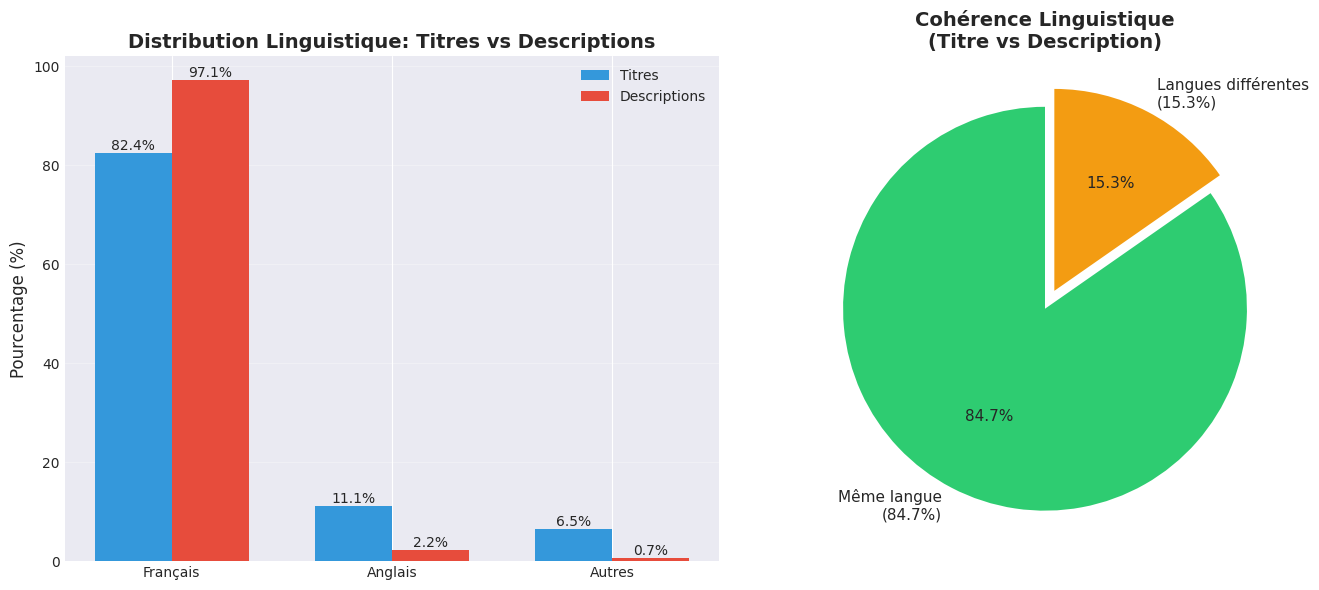

✅ Graphique sauvegardé: language_analysis.png


In [29]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Graph 1: Titres vs Descriptions
categories = ['Français', 'Anglais', 'Autres']
titres = [82.4, 11.1, 6.5]
descriptions = [97.1, 2.2, 0.7]

x = np.arange(len(categories))
width = 0.35

bars1 = axes[0].bar(x - width/2, titres, width, label='Titres', color='#3498db')
bars2 = axes[0].bar(x + width/2, descriptions, width, label='Descriptions', color='#e74c3c')

axes[0].set_ylabel('Pourcentage (%)', fontsize=12)
axes[0].set_title('Distribution Linguistique: Titres vs Descriptions', fontsize=14, fontweight='bold')
axes[0].set_xticks(x)
axes[0].set_xticklabels(categories)
axes[0].legend()
axes[0].grid(axis='y', alpha=0.3)

# Add value labels
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        axes[0].text(bar.get_x() + bar.get_width()/2., height,
                    f'{height:.1f}%', ha='center', va='bottom', fontsize=10)

# Graph 2: Mixing linguistique
labels = ['Même langue\n(84.7%)', 'Langues différentes\n(15.3%)']
sizes = [84.7, 15.3]
colors = ['#2ecc71', '#f39c12']
explode = (0, 0.1)

axes[1].pie(sizes, explode=explode, labels=labels, autopct='%1.1f%%',
            colors=colors, startangle=90, textprops={'fontsize': 11})
axes[1].set_title('Cohérence Linguistique\n(Titre vs Description)',
                  fontsize=14, fontweight='bold')

plt.tight_layout()
# Change le chemin vers ton répertoire local
plt.savefig('language_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

print("✅ Graphique sauvegardé: language_analysis.png")

In [26]:
# Cell pour analyse COMPLÈTE des 8M produits (optimisé parallèle)

import gzip
import json
import multiprocessing as mp
import warnings
from collections import Counter

from langdetect import DetectorFactory

warnings.filterwarnings('ignore')

# Set seed for reproducible language detection
DetectorFactory.seed = 0

print("🌍 Analyzing language distribution on FULL 8M dataset...")
print("(This will take 20-40 minutes with parallel processing)\n")

# Function to safely detect language
def safe_detect(text):
    try:
        if text and len(str(text).strip()) > 10:
            return detect(str(text))
        return 'unknown'
    except:
        return 'error'

# Function to process a single product (for parallel processing)
def process_product(line):
    """Process a single product and return language stats"""
    try:
        product = json.loads(line)

        # Detect title language
        title_lang = safe_detect(product['designation'])

        # Detect description language (if present)
        desc = product.get('description', '')
        desc_lang = safe_detect(desc) if desc else None

        return {
            'title_lang': title_lang,
            'desc_lang': desc_lang,
            'has_both': desc_lang is not None
        }
    except:
        return None

# Method 1: Sequential (simple, slower but guaranteed to work)
def analyze_sequential(filename, max_products=None):
    """Sequential analysis - simple but slower"""
    print("📊 Running SEQUENTIAL analysis...")
    print("   (Estimated time: 40-60 minutes)\n")

    stats = {
        'title_languages': Counter(),
        'desc_languages': Counter(),
        'both_languages': [],
        'total_processed': 0,
        'total_with_desc': 0
    }

    with gzip.open(filename, 'rt', encoding='utf-8') as f:
        for i, line in enumerate(tqdm(f, desc="Processing", unit=" products")):
            if max_products and i >= max_products:
                break

            result = process_product(line)
            if result:
                stats['total_processed'] += 1

                # Title language
                stats['title_languages'][result['title_lang']] += 1

                # Description language
                if result['desc_lang']:
                    stats['total_with_desc'] += 1
                    stats['desc_languages'][result['desc_lang']] += 1

                    # Track mixing
                    if result['title_lang'] not in ['error', 'unknown'] and \
                       result['desc_lang'] not in ['error', 'unknown']:
                        stats['both_languages'].append((result['title_lang'], result['desc_lang']))

            # Progress update every 500K
            if (i + 1) % 500000 == 0:
                print(f"   Processed {i+1:,} products...")

    return stats

# Method 2: Parallel with chunking (faster, uses all CPU cores)
def analyze_parallel_chunked(filename, chunk_size=100000):
    """Parallel analysis with chunking - FAST"""
    print("⚡ Running PARALLEL analysis (using all CPU cores)...")
    print(f"   Chunk size: {chunk_size:,} products")
    print(f"   CPU cores: {mp.cpu_count()}")
    print("   (Estimated time: 20-30 minutes)\n")

    stats = {
        'title_languages': Counter(),
        'desc_languages': Counter(),
        'both_languages': [],
        'total_processed': 0,
        'total_with_desc': 0
    }

    # Read and process in chunks
    chunk_num = 0
    with gzip.open(filename, 'rt', encoding='utf-8') as f:
        while True:
            # Read chunk
            chunk = []
            for i in range(chunk_size):
                line = f.readline()
                if not line:
                    break
                chunk.append(line)

            if not chunk:
                break

            chunk_num += 1
            print(f"   Processing chunk {chunk_num} ({len(chunk):,} products)...")

            # Process chunk in parallel
            with mp.Pool(processes=mp.cpu_count()) as pool:
                results = pool.map(process_product, chunk)

            # Aggregate results
            for result in results:
                if result:
                    stats['total_processed'] += 1

                    # Title language
                    stats['title_languages'][result['title_lang']] += 1

                    # Description language
                    if result['desc_lang']:
                        stats['total_with_desc'] += 1
                        stats['desc_languages'][result['desc_lang']] += 1

                        # Track mixing
                        if result['title_lang'] not in ['error', 'unknown'] and \
                           result['desc_lang'] not in ['error', 'unknown']:
                            stats['both_languages'].append((result['title_lang'], result['desc_lang']))

            print(f"   ✓ Chunk {chunk_num} done. Total processed: {stats['total_processed']:,}")

    return stats

# Choose method based on your preference
# RECOMMENDED: Use parallel for speed
USE_PARALLEL = True  # Set to False for sequential if parallel has issues

print("="*80)
print("STARTING FULL DATASET LANGUAGE ANALYSIS")
print("="*80)

if USE_PARALLEL:
    language_stats_full = analyze_parallel_chunked(
        TRAIN_FILE,
        chunk_size=100000  # Process 100K at a time
    )
else:
    language_stats_full = analyze_sequential(
        TRAIN_FILE,
        max_products=None  # None = all products
    )

print("\n" + "="*80)
print("✅ ANALYSIS COMPLETE!")
print("="*80)
print(f"Total products processed: {language_stats_full['total_processed']:,}")
print(f"Products with descriptions: {language_stats_full['total_with_desc']:,}")

🌍 Analyzing language distribution on FULL 8M dataset...
(This will take 20-40 minutes with parallel processing)

STARTING FULL DATASET LANGUAGE ANALYSIS
⚡ Running PARALLEL analysis (using all CPU cores)...
   Chunk size: 100,000 products
   CPU cores: 16
   (Estimated time: 20-30 minutes)

   Processing chunk 1 (100,000 products)...
   ✓ Chunk 1 done. Total processed: 100,000
   Processing chunk 2 (100,000 products)...
   ✓ Chunk 2 done. Total processed: 200,000
   Processing chunk 3 (100,000 products)...
   ✓ Chunk 3 done. Total processed: 300,000
   Processing chunk 4 (100,000 products)...
   ✓ Chunk 4 done. Total processed: 400,000
   Processing chunk 5 (100,000 products)...
   ✓ Chunk 5 done. Total processed: 500,000
   Processing chunk 6 (100,000 products)...
   ✓ Chunk 6 done. Total processed: 600,000
   Processing chunk 7 (100,000 products)...
   ✓ Chunk 7 done. Total processed: 700,000
   Processing chunk 8 (100,000 products)...
   ✓ Chunk 8 done. Total processed: 800,000
   Pr

In [27]:
# Display full dataset statistics
print("="*80)
print("🌍 FULL DATASET LANGUAGE DISTRIBUTION (8M products)")
print("="*80)

# Title languages
title_lang_counts_full = language_stats_full['title_languages']
print(f"\n📝 TITLE LANGUAGES (from {language_stats_full['total_processed']:,} products):")
print("="*80)

for i, (lang, count) in enumerate(title_lang_counts_full.most_common(20), 1):
    pct = count / language_stats_full['total_processed'] * 100
    lang_name = {
        'fr': 'French 🇫🇷',
        'en': 'English 🇬🇧',
        'de': 'German 🇩🇪',
        'es': 'Spanish 🇪🇸',
        'it': 'Italian 🇮🇹',
        'pt': 'Portuguese 🇵🇹',
        'nl': 'Dutch 🇳🇱',
        'zh-cn': 'Chinese (Simplified) 🇨🇳',
        'zh-tw': 'Chinese (Traditional) 🇹🇼',
        'ja': 'Japanese 🇯🇵',
        'ko': 'Korean 🇰🇷',
        'error': '❌ Detection Error',
        'unknown': '❓ Unknown'
    }.get(lang, lang.upper())

    print(f"  {i:2}. {lang_name:35} - {count:>9,} ({pct:5.2f}%)")

# Description languages
desc_lang_counts_full = language_stats_full['desc_languages']
if desc_lang_counts_full:
    print(f"\n📄 DESCRIPTION LANGUAGES (from {language_stats_full['total_with_desc']:,} descriptions):")
    print("="*80)

    for i, (lang, count) in enumerate(desc_lang_counts_full.most_common(20), 1):
        pct = count / language_stats_full['total_with_desc'] * 100
        lang_name = {
            'fr': 'French 🇫🇷',
            'en': 'English 🇬🇧',
            'de': 'German 🇩🇪',
            'es': 'Spanish 🇪🇸',
            'it': 'Italian 🇮🇹',
            'pt': 'Portuguese 🇵🇹',
            'nl': 'Dutch 🇳🇱',
            'zh-cn': 'Chinese (Simplified) 🇨🇳',
            'zh-tw': 'Chinese (Traditional) 🇹🇼',
            'ja': 'Japanese 🇯🇵',
            'ko': 'Korean 🇰🇷',
            'error': '❌ Detection Error',
            'unknown': '❓ Unknown'
        }.get(lang, lang.upper())

        print(f"  {i:2}. {lang_name:35} - {count:>9,} ({pct:5.2f}%)")

# Mixed language analysis
both_langs = language_stats_full['both_languages']
if both_langs:
    mixed_lang_products = [(t, d) for t, d in both_langs if t != d]
    mixed_count = len(mixed_lang_products)
    total_both = len(both_langs)

    print("\n🔀 MIXED LANGUAGE PRODUCTS:")
    print("="*80)
    print(f"  Products with different title/description languages: {mixed_count:,} ({mixed_count/total_both*100:.2f}%)")

    if mixed_count > 0:
        mixed_combos = Counter(mixed_lang_products)
        print("\n  Top 15 language combinations (Title → Description):")
        for i, ((title_lang, desc_lang), count) in enumerate(mixed_combos.most_common(15), 1):
            pct = count / mixed_count * 100
            print(f"    {i:2}. {title_lang.upper():>5} → {desc_lang.upper():<5} : {count:>7,} ({pct:4.1f}%)")

# Compare with 100K sample
print("\n📊 COMPARISON: 100K Sample vs Full 8M Dataset")
print("="*80)
print(f"{'Metric':<40} {'100K Sample':<15} {'Full 8M':<15} {'Change':<10}")
print("-"*80)

# French percentage
fr_100k = 82.36
fr_8m = (title_lang_counts_full.get('fr', 0) / language_stats_full['total_processed'] * 100)
print(f"{'French (titles)':<40} {fr_100k:>6.2f}%        {fr_8m:>6.2f}%        {fr_8m-fr_100k:>+6.2f}pp")

# English percentage
en_100k = 11.11
en_8m = (title_lang_counts_full.get('en', 0) / language_stats_full['total_processed'] * 100)
print(f"{'English (titles)':<40} {en_100k:>6.2f}%        {en_8m:>6.2f}%        {en_8m-en_100k:>+6.2f}pp")

# Chinese percentage
zh_100k = 0.0
zh_cn = title_lang_counts_full.get('zh-cn', 0)
zh_tw = title_lang_counts_full.get('zh-tw', 0)
zh_total = zh_cn + zh_tw
zh_8m = (zh_total / language_stats_full['total_processed'] * 100)
print(f"{'Chinese (titles, all variants)':<40} {zh_100k:>6.2f}%        {zh_8m:>6.2f}%        {zh_8m-zh_100k:>+6.2f}pp")

# Description availability
desc_100k = 89.1
desc_8m = (language_stats_full['total_with_desc'] / language_stats_full['total_processed'] * 100)
print(f"{'Products with descriptions':<40} {desc_100k:>6.2f}%        {desc_8m:>6.2f}%        {desc_8m-desc_100k:>+6.2f}pp")

print("\n" + "="*80)

🌍 FULL DATASET LANGUAGE DISTRIBUTION (8M products)

📝 TITLE LANGUAGES (from 8,000,000 products):
   1. French 🇫🇷                           - 5,541,518 (69.27%)
   2. English 🇬🇧                          - 1,234,257 (15.43%)
   3. German 🇩🇪                           -   410,986 ( 5.14%)
   4. Dutch 🇳🇱                            -   181,396 ( 2.27%)
   5. CA                                  -   147,196 ( 1.84%)
   6. Italian 🇮🇹                          -    91,844 ( 1.15%)
   7. RO                                  -    64,461 ( 0.81%)
   8. Spanish 🇪🇸                          -    51,801 ( 0.65%)
   9. ❓ Unknown                           -    50,697 ( 0.63%)
  10. Portuguese 🇵🇹                       -    49,654 ( 0.62%)
  11. NO                                  -    28,590 ( 0.36%)
  12. ID                                  -    22,872 ( 0.29%)
  13. AF                                  -    18,238 ( 0.23%)
  14. TL                                  -    15,822 ( 0.20%)
  15. DA             

In [28]:
# Save results to file for future reference
import json

full_results = {
    'total_products': language_stats_full['total_processed'],
    'total_with_descriptions': language_stats_full['total_with_desc'],
    'title_languages': dict(title_lang_counts_full.most_common(50)),
    'description_languages': dict(desc_lang_counts_full.most_common(50)),
    'mixed_language_count': len([t for t, d in language_stats_full['both_languages'] if t != d]),
    'analysis_date': '2026-01-23'
}

with open('language_analysis_full_8m.json', 'w') as f:
    json.dump(full_results, f, indent=2)

print("✅ Results saved to: language_analysis_full_8m.json")

✅ Results saved to: language_analysis_full_8m.json


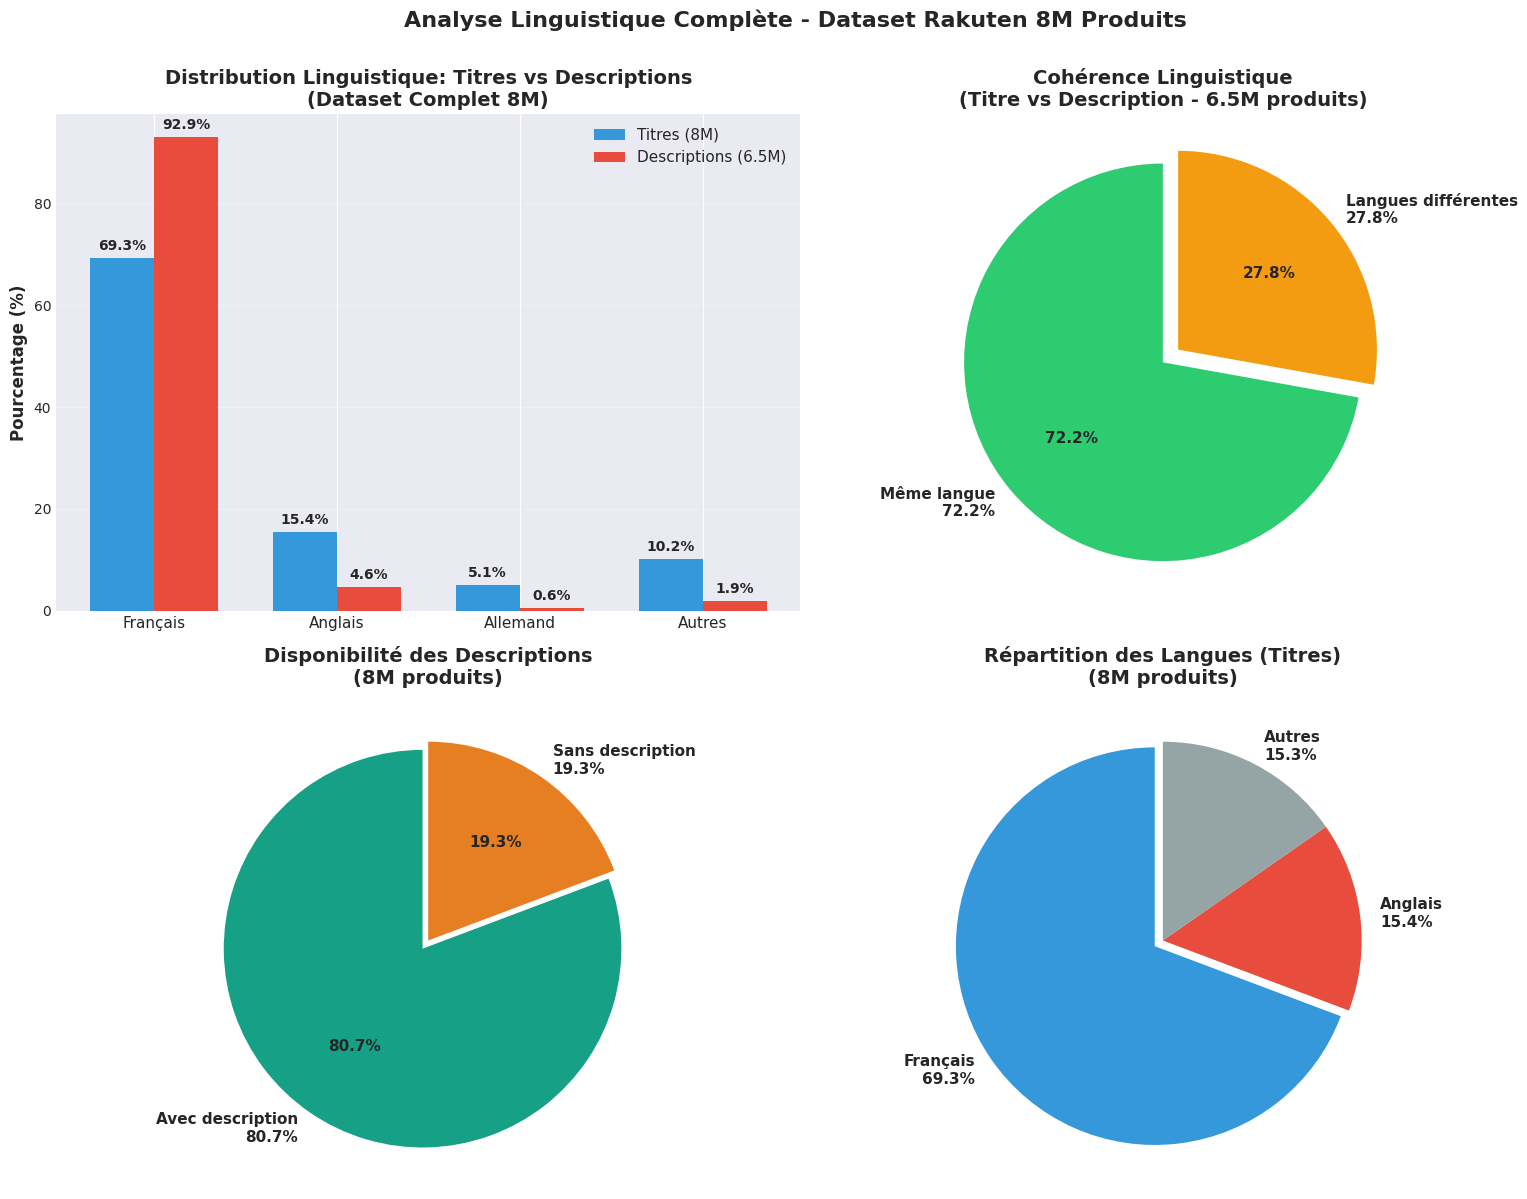

✅ Graphique sauvegardé: language_analysis_8m_complete.png

📊 RÉSUMÉ DES DONNÉES UTILISÉES:
   Titres analysés: 8,000,000
   Descriptions analysées: 6,458,595 (80.73%)
   Français (titres): 69.27%
   Français (descriptions): 92.92%
   Mixing linguistique: 27.83%


In [32]:
import matplotlib.pyplot as plt
import numpy as np

# ============================================================================
# DONNÉES RÉELLES DE L'ANALYSE 8M (depuis ton output)
# ============================================================================

# Données titres (8M produits)
title_data = {
    'French': {'count': 5_541_518, 'pct': 69.27},
    'English': {'count': 1_234_257, 'pct': 15.43},
    'German': {'count': 410_986, 'pct': 5.14},
    'Dutch': {'count': 181_396, 'pct': 2.27},
    'Other': {'count': 632_843, 'pct': 7.89}  # Somme des autres
}

# Données descriptions (6.46M descriptions)
desc_data = {
    'French': {'count': 6_001_013, 'pct': 92.92},
    'English': {'count': 296_316, 'pct': 4.59},
    'German': {'count': 38_881, 'pct': 0.60},
    'Other': {'count': 122_385, 'pct': 1.89}  # Somme des autres
}

# Données mixing (parmi 6.46M avec description et titre)
mixing_data = {
    'same': 72.17,  # Même langue
    'different': 27.83  # Langues différentes
}

# Données description availability
desc_availability = {
    'with_desc': 80.73,  # 6,458,595 / 8,000,000
    'without_desc': 19.27
}

# ============================================================================
# GRAPHIQUES
# ============================================================================

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# ============================================================================
# Graph 1: Titres vs Descriptions (Top 3 + Other)
# ============================================================================
categories = ['Français', 'Anglais', 'Allemand', 'Autres']

# Extraire les pourcentages
titres_pct = [
    title_data['French']['pct'],
    title_data['English']['pct'],
    title_data['German']['pct'],
    title_data['Dutch']['pct'] + title_data['Other']['pct']
]

descriptions_pct = [
    desc_data['French']['pct'],
    desc_data['English']['pct'],
    desc_data['German']['pct'],
    desc_data['Other']['pct']
]

x = np.arange(len(categories))
width = 0.35

bars1 = axes[0, 0].bar(x - width/2, titres_pct, width, label='Titres (8M)', color='#3498db')
bars2 = axes[0, 0].bar(x + width/2, descriptions_pct, width, label='Descriptions (6.5M)', color='#e74c3c')

axes[0, 0].set_ylabel('Pourcentage (%)', fontsize=12, fontweight='bold')
axes[0, 0].set_title('Distribution Linguistique: Titres vs Descriptions\n(Dataset Complet 8M)',
                     fontsize=14, fontweight='bold')
axes[0, 0].set_xticks(x)
axes[0, 0].set_xticklabels(categories, fontsize=11)
axes[0, 0].legend(fontsize=11)
axes[0, 0].grid(axis='y', alpha=0.3)

# Add value labels
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        axes[0, 0].text(bar.get_x() + bar.get_width()/2., height + 1,
                       f'{height:.1f}%', ha='center', va='bottom', fontsize=10, fontweight='bold')

# ============================================================================
# Graph 2: Mixing Linguistique
# ============================================================================
labels_mix = [f'Même langue\n{mixing_data["same"]:.1f}%',
              f'Langues différentes\n{mixing_data["different"]:.1f}%']
sizes_mix = [mixing_data['same'], mixing_data['different']]
colors_mix = ['#2ecc71', '#f39c12']
explode_mix = (0, 0.1)

wedges, texts, autotexts = axes[0, 1].pie(
    sizes_mix,
    explode=explode_mix,
    labels=labels_mix,
    autopct='%1.1f%%',
    colors=colors_mix,
    startangle=90,
    textprops={'fontsize': 11, 'fontweight': 'bold'}
)

axes[0, 1].set_title('Cohérence Linguistique\n(Titre vs Description - 6.5M produits)',
                     fontsize=14, fontweight='bold')

# ============================================================================
# Graph 3: Description Availability
# ============================================================================
labels_desc = [f'Avec description\n{desc_availability["with_desc"]:.1f}%',
               f'Sans description\n{desc_availability["without_desc"]:.1f}%']
sizes_desc = [desc_availability['with_desc'], desc_availability['without_desc']]
colors_desc = ['#16a085', '#e67e22']
explode_desc = (0.05, 0)

wedges2, texts2, autotexts2 = axes[1, 0].pie(
    sizes_desc,
    explode=explode_desc,
    labels=labels_desc,
    autopct='%1.1f%%',
    colors=colors_desc,
    startangle=90,
    textprops={'fontsize': 11, 'fontweight': 'bold'}
)

axes[1, 0].set_title('Disponibilité des Descriptions\n(8M produits)',
                     fontsize=14, fontweight='bold')

# ============================================================================
# Graph 4: French Dominance (Pie Chart)
# ============================================================================
labels_fr = [
    f'Français\n{title_data["French"]["pct"]:.1f}%',
    f'Anglais\n{title_data["English"]["pct"]:.1f}%',
    f'Autres\n{title_data["German"]["pct"] + title_data["Dutch"]["pct"] + title_data["Other"]["pct"]:.1f}%'
]
sizes_fr = [
    title_data['French']['pct'],
    title_data['English']['pct'],
    title_data['German']['pct'] + title_data['Dutch']['pct'] + title_data['Other']['pct']
]
colors_fr = ['#3498db', '#e74c3c', '#95a5a6']
explode_fr = (0.05, 0, 0)

wedges3, texts3, autotexts3 = axes[1, 1].pie(
    sizes_fr,
    explode=explode_fr,
    labels=labels_fr,
    autopct='',
    colors=colors_fr,
    startangle=90,
    textprops={'fontsize': 11, 'fontweight': 'bold'}
)

axes[1, 1].set_title('Répartition des Langues (Titres)\n(8M produits)',
                     fontsize=14, fontweight='bold')

# ============================================================================
# Finalize and save
# ============================================================================
plt.suptitle('Analyse Linguistique Complète - Dataset Rakuten 8M Produits',
             fontsize=16, fontweight='bold', y=0.995)

plt.tight_layout(rect=[0, 0, 1, 0.99])
plt.savefig('language_analysis_8m_complete.png', dpi=300, bbox_inches='tight')
plt.show()

print("✅ Graphique sauvegardé: language_analysis_8m_complete.png")
print("\n📊 RÉSUMÉ DES DONNÉES UTILISÉES:")
print("   Titres analysés: 8,000,000")
print("   Descriptions analysées: 6,458,595 (80.73%)")
print(f"   Français (titres): {title_data['French']['pct']:.2f}%")
print(f"   Français (descriptions): {desc_data['French']['pct']:.2f}%")
print(f"   Mixing linguistique: {mixing_data['different']:.2f}%")